Urządzenie: cuda

Model                  | MAE      | RMSE    
Naiwny (t-1)           | 5.436    | 6.507   
Średnia ruchoma (7d)   | 5.446    | 6.416   
Sezonowy (t-7)         | 3.207    | 4.072   
Model GRU              | 2.913    | 3.545   


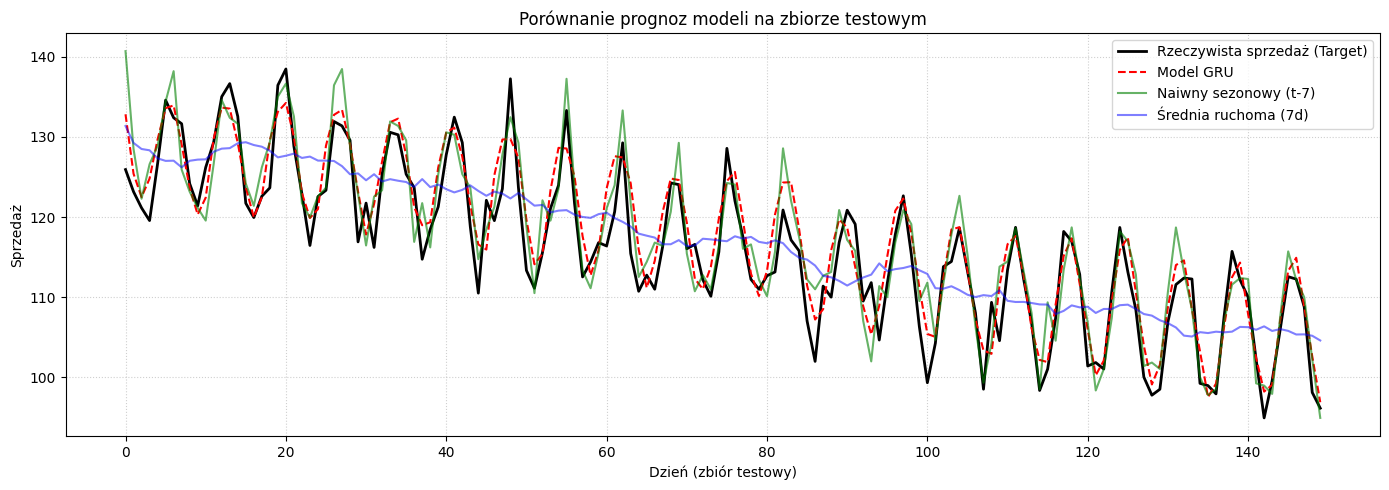

In [1]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt


torch.manual_seed(0)
np.random.seed(0)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Urządzenie:', DEVICE)


def generuj_sprzedaz(n=1000):
    t = np.arange(n)
    trend = 0.02 * t
    tygodniowa = 8 * np.sin(2 * np.pi * t / 7)
    roczna = 15 * np.sin(2 * np.pi * t / 365)
    szum = np.random.randn(n) * 3
    return (100 + trend + tygodniowa + roczna + szum).astype(np.float32)

seria = generuj_sprzedaz(1000)


n = len(seria)
i_tr = int(0.7 * n)
i_va = int(0.85 * n)

mu, sd = seria[:i_tr].mean(), seria[:i_tr].std()
s = (seria - mu) / sd    


OKNO = 28

def zrob_okna(s, okno, i_lo, i_hi):
    X, Y = [], []
    for i in range(max(okno, i_lo), i_hi):
        X.append(s[i-okno:i])
        Y.append(s[i])
    return np.array(X, np.float32)[..., None], np.array(Y, np.float32)[:, None]

Xtr, Ytr = zrob_okna(s, OKNO, OKNO, i_tr)
Xva, Yva = zrob_okna(s, OKNO, i_tr, i_va)
Xte, Yte = zrob_okna(s, OKNO, i_va, n)

to_t = lambda a: torch.tensor(a).to(DEVICE)
Xtr, Ytr, Xva, Yva, Xte, Yte = map(to_t, [Xtr, Ytr, Xva, Yva, Xte, Yte])


class ModelGRU(nn.Module):
    def __init__(self, hidden=32):
        super().__init__()
        self.rnn = nn.GRU(1, hidden, batch_first=True)
        self.fc = nn.Linear(hidden, 1)

    def forward(self, x):
        out, _ = self.rnn(x)
        return self.fc(out[:, -1, :])

def trenuj(model, epoki=40, lr=1e-2, batch=64):
    model = model.to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    L = nn.MSELoss()
    best = 1e9
    best_state = None
    hist = []

    for ep in range(epoki):
        model.train()
        perm = torch.randperm(len(Xtr))
        for i in range(0, len(Xtr), batch):
            idx = perm[i:i+batch]
            opt.zero_grad()
            L(model(Xtr[idx]), Ytr[idx]).backward()
            opt.step()

        model.eval()
        with torch.no_grad():
            v = L(model(Xva), Yva).item()
        hist.append(v)

        if v < best:
            best = v
            best_state = {k: val.clone() for k, val in model.state_dict().items()}

    model.load_state_dict(best_state)
    return model, hist

model_gru, hist_gru = trenuj(ModelGRU(32))


model_gru.eval()
with torch.no_grad():
    y_pred_gru_norm = model_gru(Xte).cpu().numpy().flatten()


y_true = Yte.cpu().numpy().flatten() * sd + mu
y_pred_gru = y_pred_gru_norm * sd + mu


Xte_orig = Xte.cpu().numpy().squeeze(-1) * sd + mu


y_pred_naive = Xte_orig[:, -1]


y_pred_ma7 = Xte_orig[:, -7:].mean(axis=1)


y_pred_snaive = Xte_orig[:, -7]


def mae(y_t, y_p):
    return np.mean(np.abs(y_t - y_p))

def rmse(y_t, y_p):
    return np.sqrt(np.mean((y_t - y_p) ** 2))


wyniki = {
    'Naiwny (t-1)': (mae(y_true, y_pred_naive), rmse(y_true, y_pred_naive)),
    'Średnia ruchoma (7d)': (mae(y_true, y_pred_ma7), rmse(y_true, y_pred_ma7)),
    'Sezonowy (t-7)': (mae(y_true, y_pred_snaive), rmse(y_true, y_pred_snaive)),
    'Model GRU': (mae(y_true, y_pred_gru), rmse(y_true, y_pred_gru))
}


print("\n" + "="*45)
print(f"{'Model':<22} | {'MAE':<8} | {'RMSE':<8}")
print("="*45)
for nazwa, (m, r) in wyniki.items():
    print(f"{nazwa:<22} | {m:<8.3f} | {r:<8.3f}")
print("="*45)


plt.figure(figsize=(14, 5))
plt.plot(y_true, label='Rzeczywista sprzedaż (Target)', color='black', linewidth=2)
plt.plot(y_pred_gru, label='Model GRU', color='red', linestyle='--')
plt.plot(y_pred_snaive, label='Naiwny sezonowy (t-7)', color='green', alpha=0.6)
plt.plot(y_pred_ma7, label='Średnia ruchoma (7d)', color='blue', alpha=0.5)

plt.title('Porównanie prognoz modeli na zbiorze testowym')
plt.xlabel('Dzień (zbiór testowy)')
plt.ylabel('Sprzedaż')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()